In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 messages:")
print(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 2)

First 5 messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
df.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Number of messages: 5572

Missing values:
label      0
message    0
dtype: int64

Message counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Dataset shape after cleaning: (5169, 2)


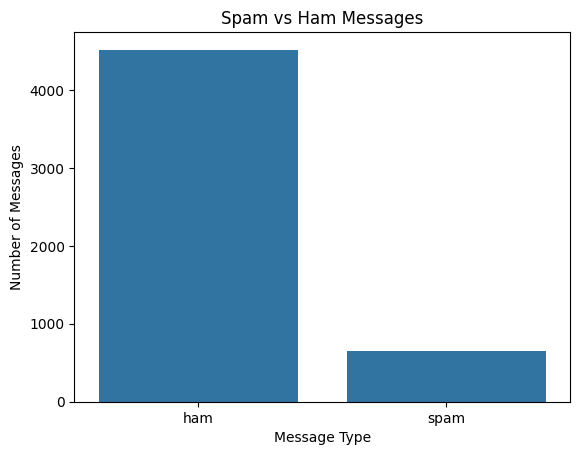

In [4]:

# Check the dataset size
print("Number of messages:", len(df))

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check spam and ham counts
print("\nMessage counts:")
print(df["label"].value_counts())

# Remove missing values and duplicate messages
df = df.dropna()
df = df.drop_duplicates()

print("\nDataset shape after cleaning:", df.shape)

# Visualize the class distribution
sns.countplot(data=df, x="label")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()


In [5]:

# Separate messages and labels
X = df["message"]
y = df["label"]

# Convert labels into numbers
y = y.map({"ham": 0, "spam": 1})

# Split data before learning the vocabulary
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Text conversion completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)


Text conversion completed!
Training feature shape: (4135, 7414)
Testing feature shape: (1034, 7414)


In [6]:

model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Spam detection model trained successfully!")


Spam detection model trained successfully!


Model Accuracy: 95.65 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       903
        Spam       0.98      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034



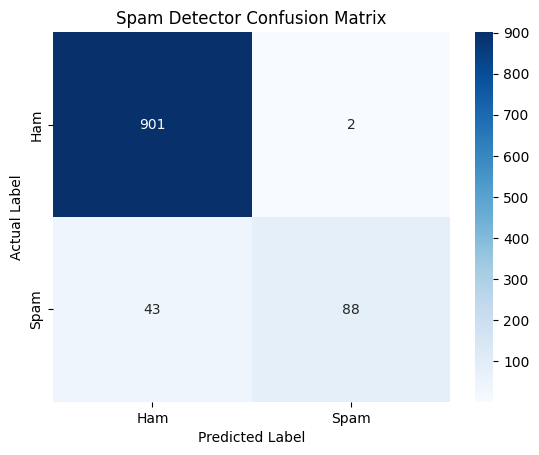

In [7]:

# Predict test messages
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Spam Detector Confusion Matrix")
plt.show()


In [8]:

def detect_spam(message):

    # Convert the input message into TF-IDF features
    message_tfidf = vectorizer.transform([message])

    # Predict the message category
    prediction = model.predict(message_tfidf)[0]

    # Get estimated spam probability
    spam_probability = model.predict_proba(message_tfidf)[0][1]

    if prediction == 1:
        print("Result: SPAM")
    else:
        print("Result: NOT SPAM (HAM)")

    print(
        "Estimated spam probability:",
        round(spam_probability * 100, 2),
        "%"
    )


# Try your own message
message = input("Enter a message: ")

detect_spam(message)


Enter a message: Hi, are we meeting tomorrow at college?
Result: NOT SPAM (HAM)
Estimated spam probability: 4.03 %
